# 04 - Composition and differential expression

Compares COVID-19 patients with healthy donors in two ways: whether the proportions of cell types change (composition), and whether genes change within a cell type (expression). In both, the donor is the unit of replication, not the cell.

**Data** 
- GSE150728 (Wilk et al. 2020, *Nature Medicine*), PBMCs from COVID-19 patients and healthy donors.

**Input**
- `results/annotation/annotated.h5ad`

**Outputs** (in `results/de/`)
- `proportions_per_donor.csv`, `composition_tests.csv`
- `pseudobulk_<cell_type>.csv` for six cell types, `de_summary.csv`
- `hallmark_enrichment.csv`

Extra packages, installed once: `pip install pydeseq2 gseapy`. The Hallmark gene sets are downloaded from Enrichr.

## Setup

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import gseapy as gp
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
from adjustText import adjust_text

RESULTS = "../results"
os.makedirs(f"{RESULTS}/de", exist_ok=True)

adata = sc.read_h5ad(f"{RESULTS}/annotation/annotated.h5ad")
adata

AnnData object with n_obs × n_vars = 46019 × 40448
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'sample', 'donor', 'condition', 'doublet_score', 'predicted_doublet', 'leiden_0.5', 'leiden_1.0', 'genes_per_umi', 'cell_type', 'celltypist', 'celltypist_cell'
    var: 'gene_name', 'mt', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'cell_type_colors', 'condition_colors', 'hvg', 'leiden_0.5', 'leiden_0.5_colors', 'leiden_1.0', 'leiden_1.0_colors', 'log1p', 'neighbors', 'pca', 'rank_genes_groups', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap', 'X_umap_uncorrected'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

## 1. Donors

covid_555_1 and covid_555_2 come from the same patient (C1) sampled at day 9 on supplemental oxygen and at day 11 after intubation. They share the donor ID `covid_555` from the sample sheet, so grouping by donor combines them and each person counts once. Keeping only one of the two samples would be a reasonable alternative.

In [2]:
(adata.obs.groupby("donor", observed=True)["sample"]
    .agg(lambda s: ", ".join(sorted(s.astype(str).unique())))
    .to_frame("samples"))

,samples
donor,
HIP002,HIP002
HIP015,HIP015
HIP023,HIP023
HIP043,HIP043
HIP044,HIP044
HIP045,HIP045
covid_555,"covid_555_1, covid_555_2"
covid_556,covid_556
covid_557,covid_557


## 2. Cell-type proportions per donor

Counts are converted to percentages of each donor's cells, since donors contributed different total numbers of cells.

In [3]:
counts = pd.crosstab(adata.obs["donor"], adata.obs["cell_type"])    # cells per donor per type
props = counts.div(counts.sum(axis=1), axis=0) * 100                # % of each donor's cells
props["condition"] = adata.obs.groupby("donor", observed=True)["condition"].first()

display(counts.sum(axis=1).rename_axis("donor").to_frame("cells"))
props.round(1)

,cells
donor,
HIP002,2046
HIP015,2298
HIP023,3495
HIP043,5465
HIP044,4159
HIP045,2258
covid_555,8186
covid_556,1718
covid_557,7023


cell_type,B cell,CD14 monocyte,CD16 monocyte,CD4 T,CD8 T,Dendritic cell,Developing neutrophil,NK,Neutrophil,Plasmablast,Platelet,Progenitor,Proliferating,Red blood cell,pDC,condition
donor,,,,,,,,,,,,,,,,
HIP002,7.9,32.9,7.7,14.0,12.4,1.6,0.2,17.5,1.1,0.3,0.7,0.9,0.7,0.8,1.3,Healthy
HIP015,12.8,13.8,3.5,25.9,23.8,1.8,0.0,12.9,1.0,0.2,1.1,0.2,1.0,0.6,1.3,Healthy
HIP023,8.3,6.1,1.1,54.5,15.4,0.7,0.0,11.1,0.4,0.3,0.2,0.4,0.7,0.3,0.4,Healthy
HIP043,9.4,3.0,3.8,17.1,28.1,0.6,0.0,35.1,0.0,0.8,0.2,0.2,1.2,0.1,0.5,Healthy
HIP044,10.6,11.0,9.4,43.6,7.1,1.4,0.0,13.3,0.1,0.8,0.4,0.6,0.9,0.2,0.6,Healthy
HIP045,7.5,9.5,2.9,40.2,20.1,1.4,0.2,13.4,0.1,0.5,0.1,0.6,0.6,2.1,0.7,Healthy
covid_555,5.7,39.8,3.5,11.6,13.7,0.4,1.6,10.6,0.6,8.9,1.6,0.4,0.9,0.4,0.4,COVID
covid_556,20.1,12.6,0.2,32.4,11.4,0.2,0.1,12.2,0.3,7.0,1.0,0.1,2.0,0.5,0.0,COVID
covid_557,6.5,15.7,0.5,41.6,13.9,0.3,0.3,6.5,0.3,5.6,1.7,0.7,4.9,1.4,0.1,COVID


12 donors (6 COVID, 6 healthy), with 1,718 to 8,186 cells each. Plasmablasts are 0.2-0.8% in every healthy donor and 5.6-38.8% in five of six COVID patients (covid_558 is at 38.8%). Healthy donors also vary a lot on their own, e.g. 14-54% CD4 T cells, so some apparent differences may just be normal variation between people.

covid_561 doesn't follow the general COVID pattern: few plasmablasts (0.9%), many CD16 monocytes (9.9%) and the highest CD14 monocyte share (56.6%).

Proportions in each row add up to 100%, so a large increase in one cell type (like plasmablasts in covid_558) pushes the others down even if their absolute numbers didn't change. Tools like scCODA or propeller account for this; the simple test below doesn't.

## 3. Testing each cell type

Each cell type is compared between the 6 COVID and 6 healthy donors with a Mann-Whitney U test (rank-based, so one extreme donor has limited influence), then corrected for testing 15 cell types with Benjamini-Hochberg. The `fdr` column (the adjusted p-value) is the one used for significance, with FDR < 0.05 counted as significant. With 6 vs 6 donors the smallest possible p-value is about 0.002, reached only when the groups don't overlap at all.

In [4]:
cell_types = [c for c in props.columns if c != "condition"]
is_covid = props["condition"] == "COVID"

rows = []
for ct in cell_types:
    cov, hea = props.loc[is_covid, ct], props.loc[~is_covid, ct]
    p = mannwhitneyu(cov, hea, alternative="two-sided").pvalue
    rows.append({"cell_type": ct, "median_covid": cov.median(), "median_healthy": hea.median(), "p": p})

comp = pd.DataFrame(rows).set_index("cell_type")
comp["fdr"] = multipletests(comp["p"], method="fdr_bh")[1]
comp = comp.sort_values("p").round(3)
comp

,median_covid,median_healthy,p,fdr
cell_type,,,,
Plasmablast,7.658,0.401,0.002,0.032
Platelet,1.661,0.307,0.004,0.032
Developing neutrophil,0.282,0.022,0.012,0.062
CD14 monocyte,20.035,10.279,0.041,0.103
NK,8.548,13.382,0.041,0.103
pDC,0.304,0.631,0.041,0.103
B cell,6.060,8.819,0.065,0.139
CD8 T,11.177,17.728,0.093,0.175
CD16 monocyte,0.966,3.647,0.180,0.269


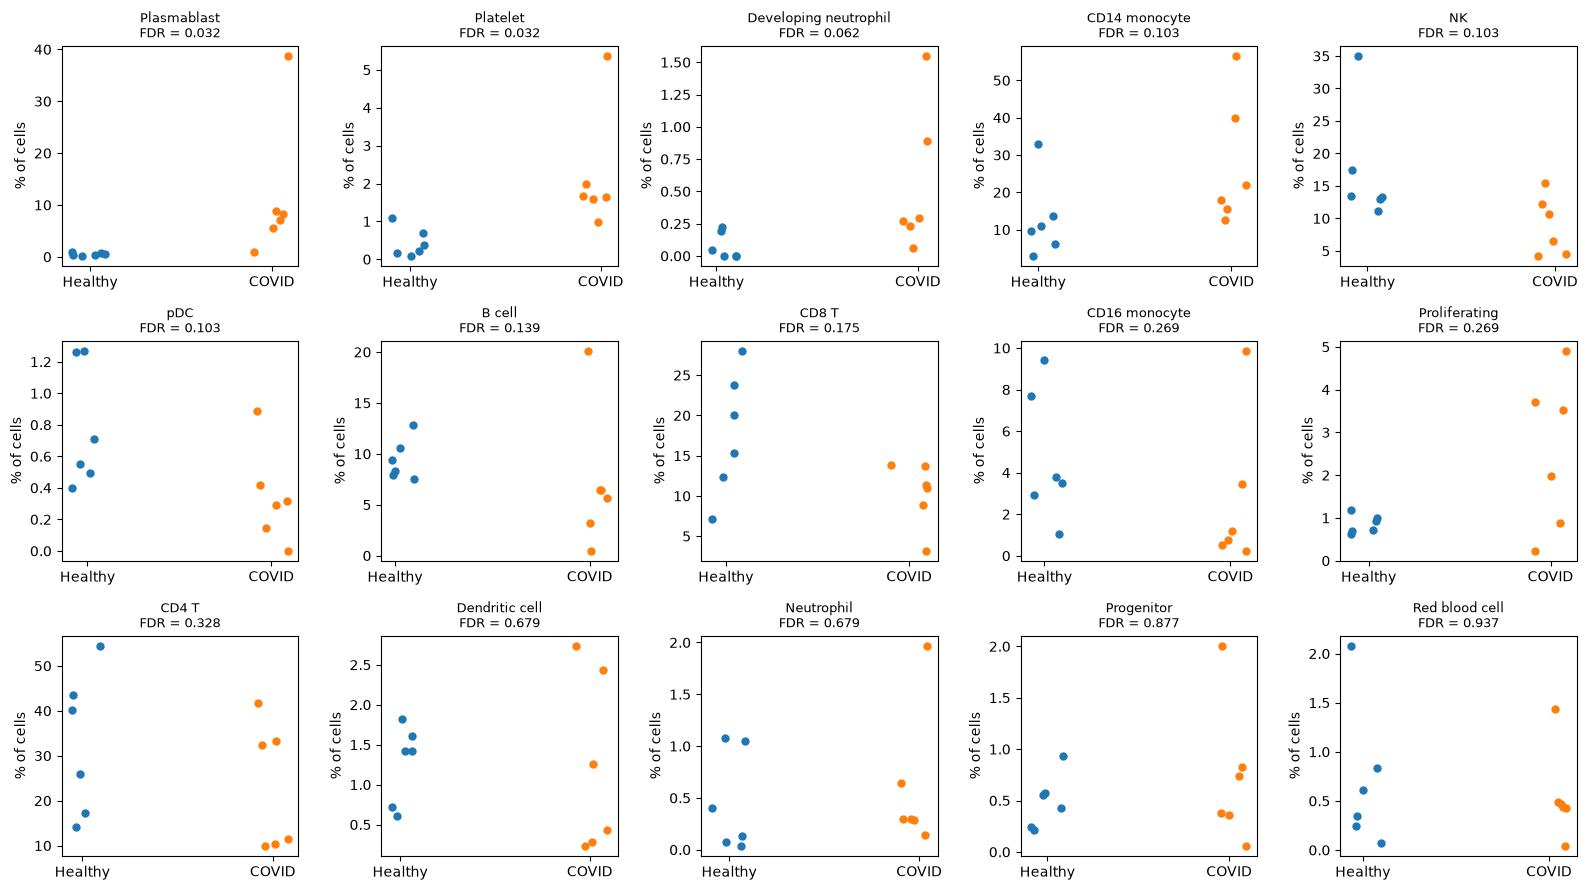

In [5]:
rng = np.random.default_rng(0)   # fixed jitter so the plot looks the same every run

fig, axes = plt.subplots(3, 5, figsize=(16, 9))
for ax, ct in zip(axes.flat, comp.index):
    for i, cond in enumerate(["Healthy", "COVID"]):
        vals = props.loc[props["condition"] == cond, ct]
        ax.scatter(i + rng.uniform(-0.1, 0.1, len(vals)), vals, s=25)
    ax.set_xticks([0, 1], ["Healthy", "COVID"])
    ax.set_title(f"{ct}\nFDR = {comp.loc[ct, 'fdr']}", fontsize=9)
    ax.set_ylabel("% of cells")
plt.tight_layout()
plt.show()

Plasmablasts (median 7.7% vs 0.4%) and platelets (1.7% vs 0.3%) are significantly higher in COVID (FDR 0.032). Plasmablasts don’t overlap at all between groups; for platelets only one pair is out of order (HIP015 at 1.1% vs covid_556 at 1.0%). Developing neutrophils (FDR 0.062) and CD14 monocytes are higher in COVID, and NK cells and pDCs are lower (each p = 0.041), but after correcting for 15 tests their FDR is above 0.05 (0.062-0.10 in the table and panel titles), so they aren't counted as significant.

CD16 monocytes are lower in five of six patients, but covid_561 (9.9%) is above most healthy donors, and with six donors per group that one patient is enough to remove most of the evidence (FDR 0.27).

These directions match what Wilk et al. report (plasmablast expansion, fewer CD16 monocytes, pDCs and NK cells, developing neutrophils in severe COVID); in the paper, CD16 monocyte and NK depletion was significant only in ventilated patients. With this many donors, only the two largest shifts are significant after correction.

## 4. Pseudobulk differential expression in CD14 monocytes

Within one cell type, raw counts are summed per donor, giving one column per donor like a bulk RNA-seq experiment. DESeq2 then compares COVID with healthy using the donors as replicates. CD14 monocytes are the largest myeloid group, so they are done step by step first.

In [6]:
ct = "CD14 monocyte"
sub = adata[adata.obs["cell_type"] == ct]
donors = sub.obs["donor"].astype(str)

# Sum raw counts per donor: rows = donors, columns = Ensembl IDs (unique, unlike gene names)
pb = pd.DataFrame(
    {d: np.asarray(sub[donors == d].layers["counts"].sum(axis=0)).ravel() for d in donors.unique()},
    index=sub.var_names,
).T
meta = sub.obs.groupby("donor", observed=True)["condition"].first().astype(str).loc[pb.index].to_frame()

print(f"Pseudobulk matrix: {pb.shape[0]} donors x {pb.shape[1]} genes")
donors.value_counts().rename_axis("donor").to_frame("CD14 monocytes")

Pseudobulk matrix: 12 donors x 40448 genes


,CD14 monocytes
donor,
covid_555,3259
covid_561,1984
covid_557,1100
covid_558,769
HIP002,674
HIP044,459
covid_559,429
HIP015,316
covid_556,216


Every donor contributes at least 162 CD14 monocytes (HIP043) and up to 3,259 (covid_555). DESeq2's size factors adjust for the different totals.

Genes with at least 10 counts in at least 6 donors (the size of each group) are kept. Barely detected genes can't give reliable results but would still count toward the multiple-testing correction.

In [7]:
pb_f = pb.loc[:, (pb >= 10).sum(axis=0) >= 6]
print("Genes kept:", pb_f.shape[1])

dds = DeseqDataSet(counts=pb_f, metadata=meta, design="~condition", quiet=True)
dds.deseq2()
stats = DeseqStats(dds, contrast=["condition", "COVID", "Healthy"], quiet=True)
stats.summary()

res = stats.results_df
res["gene"] = res.index.map(adata.var["gene_name"])
res.sort_values("padj").head(25)[["gene", "baseMean", "log2FoldChange", "padj"]]

Genes kept: 9674


,gene,baseMean,log2FoldChange,padj
gene_id,,,,
ENSG00000143546.10,S100A8,18489.755136,2.216391,3.939176e-32
ENSG00000145287.11,PLAC8,623.513535,2.750916,3.939176e-32
ENSG00000137193.14,PIM1,392.608592,2.806928,3.891648e-26
ENSG00000130164.15,LDLR,125.812852,2.105424,4.215216e-24
ENSG00000059728.11,MXD1,204.781762,1.453367,4.016305e-22
ENSG00000135842.17,NIBAN1,398.497116,1.661884,7.149166e-22
ENSG00000110079.19,MS4A4A,78.425832,3.519893,1.678282e-21
ENSG00000120885.22,CLU,491.309737,6.055965,6.456065e-19
ENSG00000113749.8,HRH2,309.758442,1.127701,7.742108e-19


9,674 genes are tested. A positive log2 fold change means higher in COVID. Most top genes go up: S100A8, VCAN and PLAC8 (inflammatory and early-monocyte genes), FAM20A, MCEMP1, CES1, MS4A4A and CLU (CLU and FAM20A up about 64-fold), and metabolic genes like PKM and LDLR.

S100A8 is also very abundant in neutrophils, so part of its increase could be ambient RNA from the developing neutrophils.

Significant (padj < 0.05, |log2FC| > 1): 415 | up: 281 | down: 134


,baseMean,log2FoldChange,padj
gene,,,
IFI44L,307.7496,3.5961,0.0000
IFITM3,976.4147,3.1913,0.0000
MX1,736.0502,2.7977,0.0015
ISG15,292.5443,2.2023,0.0059
HLA-DRA,2136.1019,-1.3671,0.0002
HLA-DRB1,1573.0773,-1.7093,0.0000
HLA-DPA1,860.9836,-1.5051,0.0112
CD74,3886.4021,-1.1341,0.0000
IL1B,71.8776,-0.4481,0.7093


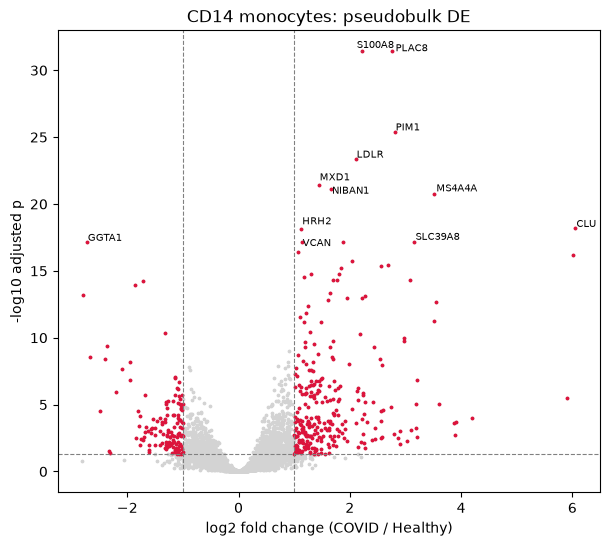

In [8]:
sig = res[(res["padj"] < 0.05) & (res["log2FoldChange"].abs() > 1)]
print("Significant (padj < 0.05, |log2FC| > 1):", len(sig),
      "| up:", (sig["log2FoldChange"] > 0).sum(), "| down:", (sig["log2FoldChange"] < 0).sum())

check = ["IFI44L", "IFITM3", "MX1", "ISG15", "IFI27",       # interferon response
         "HLA-DRA", "HLA-DRB1", "HLA-DPA1", "CD74",         # antigen presentation
         "IL1B", "TNF", "CD163"]                            # cytokines / scavenger
display(res.set_index("gene")
           .reindex([g for g in check if g in set(res["gene"])])[["baseMean", "log2FoldChange", "padj"]]
           .round(4))

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(res["log2FoldChange"], -np.log10(res["padj"]), s=3, c="lightgrey")
ax.scatter(sig["log2FoldChange"], -np.log10(sig["padj"]), s=3, c="crimson")
ax.axhline(-np.log10(0.05), ls="--", lw=0.8, c="grey")
ax.axvline(-1, ls="--", lw=0.8, c="grey")
ax.axvline(1, ls="--", lw=0.8, c="grey")

texts = [ax.text(r["log2FoldChange"], -np.log10(r["padj"]), r["gene"], fontsize=7)
         for _, r in res.nsmallest(12, "padj").iterrows()]
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="grey", lw=0.5))

ax.set_xlabel("log2 fold change (COVID / Healthy)")
ax.set_ylabel("-log10 adjusted p")
ax.set_title("CD14 monocytes: pseudobulk DE")
plt.show()

415 genes pass both cutoffs (281 up, 134 down), and the volcano plot leans to the right.

Interferon-stimulated genes are up (IFI44L log2FC 3.6, IFITM3 3.2, MX1 2.8, ISG15 2.2). MHC class II genes are down by roughly 2-3 fold (HLA-DRA, HLA-DRB1, HLA-DPA1, CD74), matching the HLA class II downregulation reported by Wilk et al. IL1B doesn’t change (padj 0.71) and TNF is lower in COVID (log2FC −1.2, though it’s expressed at low levels), consistent with the paper’s observation that blood monocytes didn’t show strong inflammatory cytokine expression. CD163 is up. IFI27 isn't in the table because it didn't pass the expression filter.

Overall, CD14 monocytes in COVID look interferon-activated, with reduced antigen presentation and no increase in IL1B or TNF.

## 5. The same test for other cell types

The steps above as a function. Donors with fewer than 10 cells of a type are left out, since summing a handful of cells gives a noisy pseudobulk, and a cell type is skipped if fewer than 3 donors per group remain.

In [9]:
def pseudobulk_de(adata, cell_type, min_cells=10, min_donors=3):
    """Pseudobulk DESeq2 (COVID vs Healthy) for one cell type, donors as replicates."""
    sub = adata[adata.obs["cell_type"] == cell_type]
    donors = sub.obs["donor"].astype(str)

    # Only donors with enough cells of this type
    n_cells = donors.value_counts()
    kept = n_cells[n_cells >= min_cells].index

    # Sum raw counts per donor (rows = donors, columns = Ensembl IDs)
    pb = pd.DataFrame(
        {d: np.asarray(sub[donors == d].layers["counts"].sum(axis=0)).ravel() for d in kept},
        index=sub.var_names,
    ).T
    meta = sub.obs.groupby("donor", observed=True)["condition"].first().astype(str).loc[pb.index].to_frame()

    n_per_group = meta["condition"].value_counts()
    if len(n_per_group) < 2 or n_per_group.min() < min_donors:
        print(f"{cell_type}: skipped, donors per group = {n_per_group.to_dict()}")
        return None

    # Genes with >= 10 counts in at least as many donors as the smaller group
    pb = pb.loc[:, (pb >= 10).sum(axis=0) >= n_per_group.min()]

    dds = DeseqDataSet(counts=pb, metadata=meta, design="~condition", quiet=True)
    dds.deseq2()
    stats = DeseqStats(dds, contrast=["condition", "COVID", "Healthy"], quiet=True)
    stats.summary()

    out = stats.results_df.copy()
    out["gene"] = out.index.map(adata.var["gene_name"])
    out.attrs["n_donors"] = n_per_group.to_dict()
    return out


def sig_genes(r):
    return set(r.index[(r["padj"] < 0.05) & (r["log2FoldChange"].abs() > 1)])

The function should reproduce the CD14 monocyte result. DESeq2 fits its model iteratively, and the function lists donors in a different order, so the numbers can differ slightly in the last decimals. The check compares what matters: the same genes tested, nearly identical fold changes and the same significant genes.

In [10]:
test = pseudobulk_de(adata, "CD14 monocyte")

assert set(test.index) == set(res.index)    # same genes tested
assert (test["log2FoldChange"] - res.loc[test.index, "log2FoldChange"]).abs().max() < 0.01
assert sig_genes(test) == sig_genes(res)    # same significant genes
print("Function matches the manual run")

Function matches the manual run


The loop covers the six cell types that every donor has in reasonable numbers. Plasmablasts are left out: healthy donors have only 4-46 each, and their increase is already captured as a composition change.

In [11]:
cell_types_de = ["CD14 monocyte", "CD16 monocyte", "CD4 T", "CD8 T", "NK", "B cell"]

de_results, summary_rows = {}, []
for ct in cell_types_de:
    r = pseudobulk_de(adata, ct)
    if r is None:
        continue
    de_results[ct] = r
    r.sort_values("padj").to_csv(f"{RESULTS}/de/pseudobulk_{ct.replace(' ', '_')}.csv")

    s = r[(r["padj"] < 0.05) & (r["log2FoldChange"].abs() > 1)]
    up, down = s[s["log2FoldChange"] > 0], s[s["log2FoldChange"] < 0]
    summary_rows.append({
        "cell_type": ct,
        "donors (COVID/Healthy)": f"{r.attrs['n_donors'].get('COVID')}/{r.attrs['n_donors'].get('Healthy')}",
        "genes_tested": len(r),
        "sig_up": len(up),
        "sig_down": len(down),
        "top_up": ", ".join(up.nlargest(5, "log2FoldChange")["gene"]),
        "top_down": ", ".join(down.nsmallest(5, "log2FoldChange")["gene"]),
    })

de_summary = pd.DataFrame(summary_rows).set_index("cell_type")
de_summary

,donors (COVID/Healthy),genes_tested,sig_up,sig_down,top_up,top_down
cell_type,,,,,,
CD14 monocyte,6/6,9674,281,134,"CLU, FAM20A, RNASE1, SERPINB10, SIGLEC1","CD1C, GGTA1, CACNA2D3, RTN1, PID1"
CD16 monocyte,5/6,6666,225,84,"CD163, RNASE2, C1QB, RGL1, FCGR1A","VMO1, RPS4XP22, TP53I11, ADGRE3, OLIG1"
CD4 T,6/6,10265,107,37,"IFIT3, IFI44L, JCHAIN, SOCS3, IGKC","NOG, MATK, MIR142HG, ENSG00000290823.1, LINC00528"
CD8 T,6/6,8338,31,13,"IFI44L, IGHM, RSAD2, IFIT3, IGKC","METRNL, MT-CYB, MT-ND6, PDE3B, MT-CO3"
NK,6/6,8267,52,23,"IFI44L, IFI44, RSAD2, IGHM, IFIT3","EPHA4, PILRB, ENSG00000291114.1, ENSG000002436..."
B cell,6/6,7464,14,2,"IFI44L, IFIT3, IFI44, OAS3, MX1","EML6, ENSG00000237550.7"


The myeloid cells change the most (CD14 monocytes 415 genes, CD16 monocytes 309), followed by CD4 T (144), NK (75), CD8 T (44) and B cells (16). CD16 monocytes ran with 5 COVID donors, since covid_556 has only 4 of them.

Interferon-stimulated genes (IFI44L, IFIT3, RSAD2, MX1, OAS3) are among the top increases in every lymphocyte type, so the interferon response is seen within each cell type rather than only through changes in composition. This compares group averages; Wilk et al. found the interferon response varied a lot between patients, with little response in some, so not every patient necessarily shows it. SIGLEC1 (CD14) and CD163, C1QB and FCGR1A (CD16) point to interferon-activated, scavenger-like monocytes.

Antibody genes (JCHAIN, IGKC, IGHM) appear among the top increases in CD4 T, CD8 T and NK cells. These cells don't make antibodies, so this is most likely ambient RNA from plasmablasts, which are much more common in COVID samples (the faint JCHAIN signal in T cells was already visible in the clustering notebook). The top decreases in CD8 T cells are mitochondrial genes, which may reflect a cell-quality difference rather than biology.

## 6. Pathway enrichment

Significant genes are tested for over-representation in the 50 MSigDB Hallmark pathways, separately for up and down genes. The background is all genes tested in that cell type, and antibody genes are removed first since they are likely ambient. Lists with fewer than 5 genes are skipped.

In [12]:
def is_ambient_ig(genes):
    return genes.str.match(r"^IG[HKL][VDJCAGEM]") | (genes == "JCHAIN")

enrich_rows = []
for ct, r in de_results.items():
    r = r[~is_ambient_ig(r["gene"].astype(str))]
    background = r["gene"].dropna().astype(str).tolist()
    s = r[(r["padj"] < 0.05) & (r["log2FoldChange"].abs() > 1)]

    for direction, genes in [("up", s[s["log2FoldChange"] > 0]), ("down", s[s["log2FoldChange"] < 0])]:
        if len(genes) < 5:
            continue
        enr = gp.enrichr(gene_list=genes["gene"].astype(str).tolist(), gene_sets="MSigDB_Hallmark_2020",
                         background=background, outdir=None)
        top = enr.results.query("`Adjusted P-value` < 0.05").head(3)
        for _, t in top.iterrows():
            genes_hit = t["Genes"].split(";")
            enrich_rows.append({"cell_type": ct, "direction": direction, "pathway": t["Term"],
                                "n_genes": len(genes_hit), "odds_ratio": round(t["Odds Ratio"], 1),
                                "padj": t["Adjusted P-value"], "example_genes": ", ".join(genes_hit[:6])})

enrichment = pd.DataFrame(enrich_rows)
enrichment

,cell_type,direction,pathway,n_genes,odds_ratio,padj,example_genes
0,CD14 monocyte,up,Interferon Gamma Response,40,11.9,4.280500e-24,"IFITM3, LGALS3BP, SAMD9L, IFITM2, TNFAIP6, FPR1"
1,CD14 monocyte,up,Interferon Alpha Response,30,20.2,8.719500e-24,"IFITM3, LGALS3BP, SAMD9L, IFITM2, SAMD9, DDX60"
2,CD14 monocyte,up,Cholesterol Homeostasis,14,12.4,3.457036e-09,"NIBAN1, STARD4, HMGCS1, CLU, FADS2, SQLE"
3,CD14 monocyte,down,Allograft Rejection,8,4.3,3.135686e-02,"CD74, CD4, HLA-DMA, HLA-DRA, RPS3A, FCGR2B"
4,CD16 monocyte,up,Interferon Gamma Response,51,19.0,2.020660e-37,"IFITM3, LGALS3BP, CD40, CDKN1A, SAMD9L, TNFAIP3"
5,CD16 monocyte,up,Interferon Alpha Response,36,28.3,1.571595e-31,"IFITM3, LGALS3BP, IFITM1, SAMD9L, SAMD9, UBE2L6"
6,CD16 monocyte,up,Inflammatory Response,27,12.8,2.953615e-17,"IFITM1, CD40, CDKN1A, AQP9, PTAFR, FPR1"
7,CD4 T,up,Interferon Gamma Response,27,27.8,4.662944e-25,"IFITM3, LGALS3BP, IFIT1, DDX60, IFI44L, IFIT3"
8,CD4 T,up,Interferon Alpha Response,20,38.6,1.456091e-21,"IFITM3, LGALS3BP, RSAD2, CNP, MX1, IFI44"
9,CD4 T,up,IL-2/STAT5 Signaling,19,19.2,8.220766e-16,"IFITM3, XBP1, CISH, RGS16, SLC2A3, CAPG"


Interferon alpha and gamma response are the top pathways in all six cell types (adjusted p from about 1e-10 to 1e-37). The two Hallmark sets share many genes (MX1, IFI44, STAT1), so this doesn't separate type I from type II interferon.

Other pathways: in CD14 monocytes, cholesterol homeostasis is up (LDLR, HMGCS1, SQLE) and "allograft rejection" is down, driven by MHC class II genes (CD74, HLA-DRA, HLA-DMA). CD16 monocytes show an inflammatory response (CD40, AQP9, PTAFR) and CD4 T cells show IL-2/STAT5 signaling (CISH, RGS16). "KRAS signaling down" only comes from 2-3 interferon genes that also belong to that set, so it isn't a separate signal.

## 7. Save

In [13]:
props.to_csv(f"{RESULTS}/de/proportions_per_donor.csv")
comp.to_csv(f"{RESULTS}/de/composition_tests.csv")
de_summary.to_csv(f"{RESULTS}/de/de_summary.csv")
enrichment.to_csv(f"{RESULTS}/de/hallmark_enrichment.csv", index=False)

## Summary

Plasmablasts and platelets are significantly expanded in COVID, and the other composition changes reported in the paper point the same way without reaching significance with 6 donors per group. Within cell types, interferon-stimulated genes are higher on average in all six major types (though the paper reports this varies between patients), and CD14 monocytes additionally show lower MHC class II and no increase in IL1B or TNF.

Each sample is only COVID or only healthy, so disease and processing batch can't be fully separated, and antibody-gene increases in T and NK cells are most likely ambient RNA.

The final results come from the pipeline (`bin/composition_de.py` on the pipeline's annotation), so the numbers differ slightly from this notebook. Plasmablasts and platelets are still the only significant composition changes, and the interferon, MHC class II and cytokine results for CD14 monocytes are within about 0.05 log2FC of the values here. NK cells are still lower in COVID (median 8.5% vs 13.6%) but no longer close to significant (p = 0.13), since the pipeline assigns about 2,700 boundary cells to CD8 T instead of NK.